# 04 — Comparaison des modèles et évaluation finale

## Objectif du notebook

1. Comparer les trois modèles sur l'ensemble de **validation**.
2. **Sélectionner** le meilleur modèle selon le **RMSE de validation**.
3. Évaluer **uniquement le modèle sélectionné** sur le **jeu de test officiel NASA**
   (dernier cycle observé de chaque moteur).
4. Sauvegarder le modèle final (`rul_model.pkl`) et les résultats (`metrics.json`).

**Règle méthodologique :** le jeu de test n'intervient **jamais** dans le choix du modèle.
Il sert seulement à estimer la performance réelle sur des moteurs totalement nouveaux.

## 1. Importations et chargement

In [1]:
# Importation des bibliothèques
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90

In [2]:
# Données préparées
validation_set = pd.read_csv("../data/processed/validation_set.csv")
test_last_cycles = pd.read_csv("../data/processed/test_last_cycles.csv")

# Transformations
preprocessing = joblib.load("../models/preprocessing.pkl")
scaler = preprocessing["scaler"]
feature_columns = preprocessing["feature_columns"]
max_rul = preprocessing["max_rul"]

X_validation = scaler.transform(validation_set[feature_columns])
y_validation = validation_set["RUL"].values

# Les trois modèles entraînés dans le notebook 03
models = {
    "Linear Regression": joblib.load("../models/candidates/linear_regression.pkl"),
    "Random Forest Regressor": joblib.load("../models/candidates/random_forest.pkl"),
    "Gradient Boosting Regressor": joblib.load("../models/candidates/gradient_boosting.pkl"),
}

In [3]:
def evaluate_model(y_true, y_predicted):
    """Calcule MAE, RMSE et R²."""
    mae = mean_absolute_error(y_true, y_predicted)
    rmse = np.sqrt(mean_squared_error(y_true, y_predicted))
    r2 = r2_score(y_true, y_predicted)
    return {"MAE": round(float(mae), 2), "RMSE": round(float(rmse), 2), "R2": round(float(r2), 4)}

## 2. Tableau comparatif sur la validation

In [4]:
validation_results = {}
validation_predictions = {}

for model_name in models:
    model = models[model_name]
    predictions = model.predict(X_validation)
    validation_predictions[model_name] = predictions
    validation_results[model_name] = evaluate_model(y_validation, predictions)

comparison_table = pd.DataFrame(validation_results).T
comparison_table

,MAE,RMSE,R2
Linear Regression,14.29,17.52,0.8219
Random Forest Regressor,10.43,14.96,0.8702
Gradient Boosting Regressor,10.32,14.58,0.8767


## 3. Graphiques de comparaison

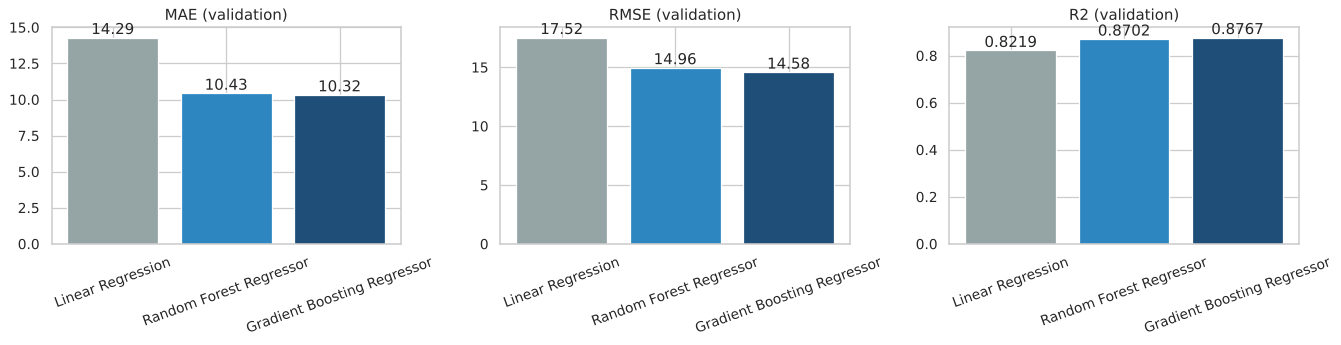

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#95a5a6", "#2e86c1", "#1f4e79"]
metric_names = ["MAE", "RMSE", "R2"]

for index, metric in enumerate(metric_names):
    axes[index].bar(comparison_table.index, comparison_table[metric], color=colors)
    axes[index].set_title(metric + " (validation)")
    axes[index].tick_params(axis="x", rotation=20)
    for position, value in enumerate(comparison_table[metric]):
        axes[index].text(position, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

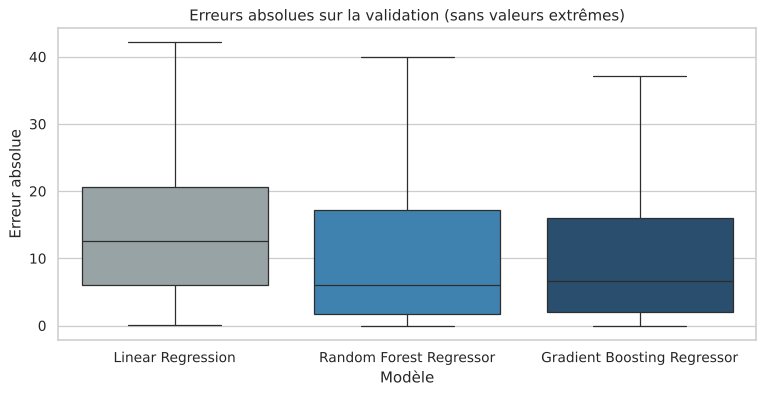

In [6]:
# Distribution des erreurs absolues des trois modèles
error_rows = []
for model_name in validation_predictions:
    absolute_errors = np.abs(validation_predictions[model_name] - y_validation)
    for error in absolute_errors:
        error_rows.append({"Modèle": model_name, "Erreur absolue": error})
errors_table = pd.DataFrame(error_rows)

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=errors_table, x="Modèle", y="Erreur absolue", showfliers=False,
            hue="Modèle", palette=colors, legend=False)
plt.title("Erreurs absolues sur la validation (sans valeurs extrêmes)")
plt.show()

### Erreur selon la proximité de la panne

En maintenance, l'erreur la plus importante est celle commise **près de la panne**.
On calcule le RMSE par tranche de RUL réel.

         Linear Regression  Random Forest Regressor  \
0-25                 15.03                     5.82   
25-50                19.34                    16.13   
50-75                21.27                    21.73   
75-100               16.17                    19.59   
100-125              16.97                    12.96   

         Gradient Boosting Regressor  
0-25                            5.06  
25-50                          14.58  
50-75                          20.75  
75-100                         19.19  
100-125                        13.11  


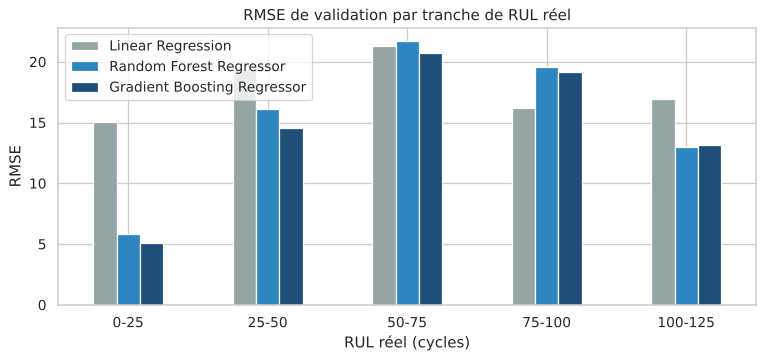

In [7]:
rul_bins = [0, 25, 50, 75, 100, 126]
rul_labels = ["0-25", "25-50", "50-75", "75-100", "100-125"]
rul_groups = pd.cut(y_validation, bins=rul_bins, labels=rul_labels, right=False)

rmse_by_group = {}
for model_name in validation_predictions:
    squared_errors = (validation_predictions[model_name] - y_validation) ** 2
    group_rmse = pd.Series(squared_errors).groupby(rul_groups, observed=False).mean() ** 0.5
    rmse_by_group[model_name] = group_rmse.round(2)

rmse_by_group = pd.DataFrame(rmse_by_group)
print(rmse_by_group)

rmse_by_group.plot(kind="bar", figsize=(10, 4), color=colors)
plt.title("RMSE de validation par tranche de RUL réel")
plt.xlabel("RUL réel (cycles)")
plt.ylabel("RMSE")
plt.xticks(rotation=0)
plt.show()

## 4. Sélection du meilleur modèle (critère : RMSE de validation)

In [8]:
best_model_name = comparison_table["RMSE"].idxmin()
best_model = models[best_model_name]

print("Modèle sélectionné :", best_model_name)
print("RMSE de validation :", comparison_table.loc[best_model_name, "RMSE"])

Modèle sélectionné : Gradient Boosting Regressor
RMSE de validation : 14.58


## 5. Évaluation finale sur le jeu de test officiel NASA

Pour chacun des 100 moteurs de test, on prédit le RUL au **dernier cycle observé**,
puis on compare avec le RUL réel donné par la NASA (`RUL_FD001.txt`).

Remarque : le RUL réel n'est **pas plafonné** ici (il peut atteindre 145), alors que le modèle
prédit au maximum environ 125. C'est la méthode d'évaluation standard de la littérature.

In [9]:
X_test = scaler.transform(test_last_cycles[feature_columns])
y_test = test_last_cycles["true_RUL"].values

# Prédiction (le RUL ne peut pas être négatif)
test_predictions = best_model.predict(X_test)
test_predictions = np.clip(test_predictions, 0, None)

test_metrics = evaluate_model(y_test, test_predictions)
print("Résultats sur le test officiel (", best_model_name, ") :", test_metrics)

Résultats sur le test officiel ( Gradient Boosting Regressor ) : {'MAE': 11.32, 'RMSE': 15.31, 'R2': 0.8642}


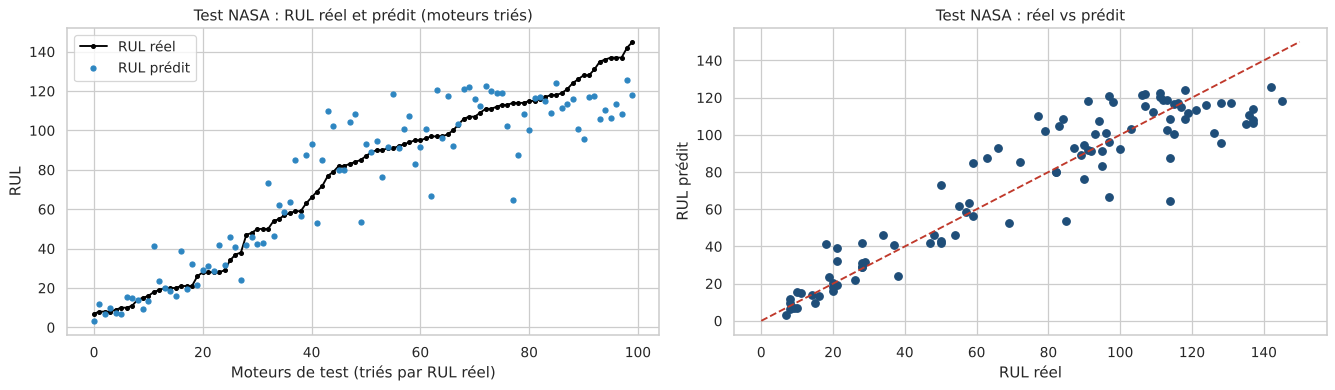

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Comparaison moteur par moteur (triée par RUL réel)
order = np.argsort(y_test)
axes[0].plot(y_test[order], "o-", markersize=3, color="black", label="RUL réel")
axes[0].plot(test_predictions[order], "o", markersize=4, color="#2e86c1", label="RUL prédit")
axes[0].set_title("Test NASA : RUL réel et prédit (moteurs triés)")
axes[0].set_xlabel("Moteurs de test (triés par RUL réel)")
axes[0].set_ylabel("RUL")
axes[0].legend()

# Nuage réel / prédit
axes[1].scatter(y_test, test_predictions, color="#1f4e79")
axes[1].plot([0, 150], [0, 150], "--", color="#c0392b")
axes[1].set_xlabel("RUL réel")
axes[1].set_ylabel("RUL prédit")
axes[1].set_title("Test NASA : réel vs prédit")
plt.tight_layout()
plt.show()

Moteurs avec une erreur absolue < 15 cycles : 72 / 100
Prédictions trop optimistes (prédit > réel) : 50 / 100


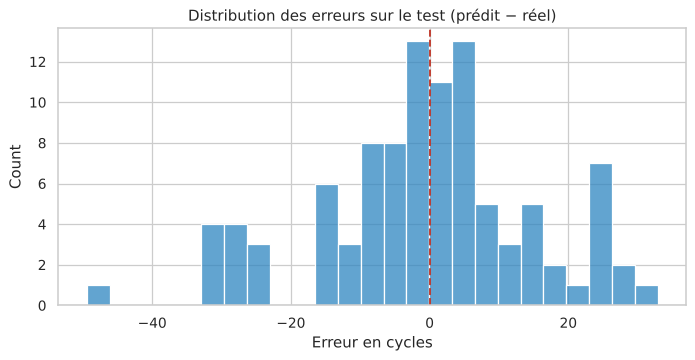

In [11]:
# Erreurs sur le test
test_errors = test_predictions - y_test
print("Moteurs avec une erreur absolue < 15 cycles :", int((np.abs(test_errors) < 15).sum()), "/ 100")
print("Prédictions trop optimistes (prédit > réel) :", int((test_errors > 0).sum()), "/ 100")

plt.figure(figsize=(9, 4))
sns.histplot(test_errors, bins=25, color="#2e86c1")
plt.axvline(0, color="#c0392b", linestyle="--")
plt.title("Distribution des erreurs sur le test (prédit − réel)")
plt.xlabel("Erreur en cycles")
plt.show()

**Interprétation :** une erreur **positive** signifie que le modèle surestime la durée de vie
(prédiction « optimiste »), ce qui est plus dangereux en maintenance qu'une erreur négative
(maintenance un peu trop tôt).

## 6. Sauvegarde du modèle final et des métriques

- `models/rul_model.pkl` : modèle sélectionné.
- `models/metrics.json` : métriques réelles, consultables par les développeurs via l'API (`GET /models/metrics`). Elles ne sont pas affichées dans l'interface destinée aux responsables de maintenance.

In [12]:
joblib.dump(best_model, "../models/rul_model.pkl", compress=3)

# Paramètres de chaque modèle (pour l'affichage dans l'application)
model_parameters = {
    "Linear Regression": {"fit_intercept": True},
    "Random Forest Regressor": {"n_estimators": 150, "max_depth": 12,
                                "min_samples_leaf": 5, "max_features": 0.5},
    "Gradient Boosting Regressor": {"n_estimators": 300, "learning_rate": 0.05,
                                    "max_depth": 4, "subsample": 0.8},
}

models_list = []
for model_name in models:
    models_list.append({
        "name": model_name,
        "parameters": model_parameters[model_name],
        "validation": validation_results[model_name],
    })

# Prédictions du test moteur par moteur (pour le graphique réel / prédit)
test_points = []
for index in range(len(test_last_cycles)):
    test_points.append({
        "unit_id": int(test_last_cycles.loc[index, "unit_id"]),
        "true_rul": int(y_test[index]),
        "predicted_rul": round(float(test_predictions[index]), 1),
    })

metrics = {
    "dataset": {
        "name": "NASA C-MAPSS FD001",
        "train_engines": len(preprocessing["train_engine_ids"]),
        "validation_engines": len(preprocessing["validation_engine_ids"]),
        "test_engines": len(test_last_cycles),
        "number_of_features": len(feature_columns),
        "max_rul": max_rul,
    },
    "models": models_list,
    "selection_criterion": "RMSE de validation",
    "selected_model": best_model_name,
    "test_results": test_metrics,
    "test_predictions": test_points,
    "rmse_by_rul_range": {
        "ranges": rul_labels,
        "values": {name: [float(v) for v in rmse_by_group[name]] for name in rmse_by_group.columns},
    },
}

with open("../models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)

print("Modèle final et metrics.json sauvegardés.")

Modèle final et metrics.json sauvegardés.


## 7. Conclusion

- Le modèle retenu est celui qui a le plus faible **RMSE de validation** (voir tableau ci-dessus).
- Sa performance sur le **jeu de test officiel NASA**, jamais utilisé pour le choix,
  est affichée en section 5 : c'est l'estimation honnête de la performance du système.
- Les erreurs des modèles à base d'arbres sont **les plus faibles près de la panne** (RUL < 25 cycles),
  ce qui est le plus important pour une application de maintenance. Elles sont plus fortes au milieu
  de la vie du moteur (50-100 cycles), période où la dégradation commence à peine à être visible.
- Le modèle final et les métriques réelles sont enregistrés pour être utilisés par l'application.